# CIFAR-10 Image Classification MLOps Project

This notebook documents acquisition, preprocessing, optimization, training, evaluation, and retraining for a 10-class image classifier.

## 1. Data acquisition
The CIFAR-10 dataset contains 60,000 32x32 RGB images from 10 real-world classes. The script downloads the official archive and creates NumPy arrays for training and testing.

In [1]:
import os
import sys
from pathlib import Path

# Google Colab setup: reset to /content before cloning or deleting anything.
if 'COLAB_RELEASE_TAG' in os.environ:
    os.chdir('/content')
    project_dir = Path('/content/kudakwashe-mlops-classification-pipeline')
    if not (project_dir / 'scripts').exists():
        !rm -rf /content/kudakwashe-mlops-classification-pipeline
        !git clone https://github.com/kudakwashechikovo17/kudakwashe-mlops-classification-pipeline.git /content/kudakwashe-mlops-classification-pipeline
    required_files = [
        project_dir / 'requirements.txt',
        project_dir / 'scripts' / 'download_cifar10.py',
        project_dir / 'src' / 'model.py',
    ]
    missing_files = [str(path) for path in required_files if not path.is_file()]
    if missing_files:
        raise RuntimeError(
            'The GitHub repository is empty or missing project files. '
            'Upload and push the project source files to the repository, then '
            'restart the Colab runtime and run all cells again. Missing: '
            + ', '.join(missing_files)
        )
    os.chdir(project_dir)
    %pip install -q -r requirements.txt

# Locate the repository root, including common Colab and notebook subdirectories.
cwd = Path.cwd()
candidates = [cwd, cwd.parent]
for path in [*cwd.parents]:
    candidates.append(path)
ROOT = next(
    (candidate for candidate in candidates
     if (candidate / 'src').exists() and (candidate / 'scripts').exists()),
    cwd,
)
sys.path.insert(0, str(ROOT))
from scripts.download_cifar10 import download_and_extract
X_train, y_train, X_test, y_test = download_and_extract()
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(50000, 32, 32, 3) (50000,) (10000, 32, 32, 3) (10000,)


## 2. Preprocessing and feature interpretation
Images are converted to RGB, resized to 32x32, converted to grayscale, and resized to 16x16. This yields 256 normalized features. Rescaling is also applied inside the classifier pipeline.

In [2]:
import numpy as np
from PIL import Image
from src.preprocessing import image_to_features

X_train_features = np.asarray([image_to_features(Image.fromarray(image)) for image in X_train])
X_test_features = np.asarray([image_to_features(Image.fromarray(image)) for image in X_test])
print(X_train_features.shape)

(50000, 768)


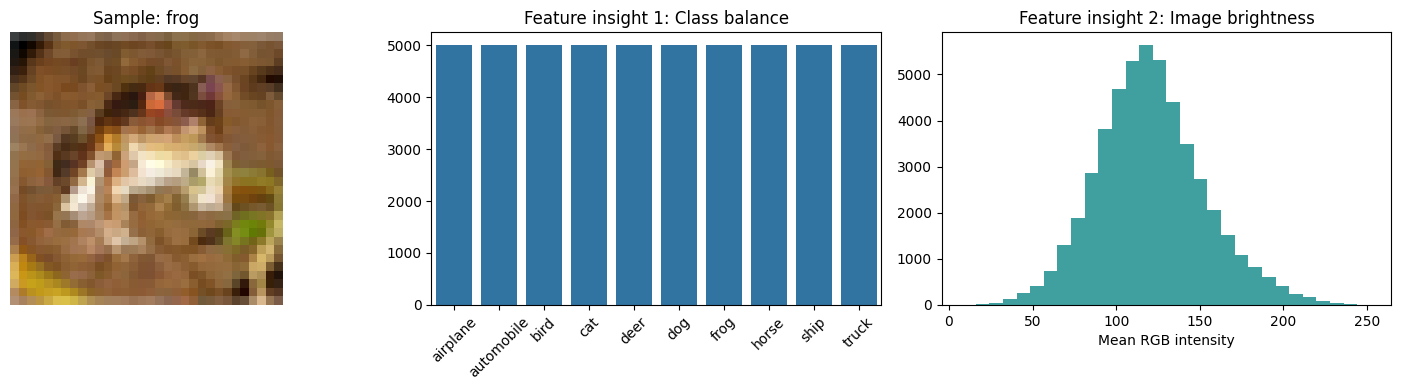

Interpretation: balanced classes reduce label bias; brightness varies by scene and can affect grayscale appearance.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.model import CIFAR10_LABELS

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(X_train[0])
axes[0].set_title(f"Sample: {CIFAR10_LABELS[y_train[0]]}")
axes[0].axis('off')

counts = np.bincount(y_train, minlength=10)
sns.barplot(x=CIFAR10_LABELS, y=counts, ax=axes[1])
axes[1].set_title('Feature insight 1: Class balance')
axes[1].tick_params(axis='x', rotation=45)

brightness = X_train.mean(axis=(1,2,3))
axes[2].hist(brightness, bins=30, color='teal', alpha=0.75)
axes[2].set_title('Feature insight 2: Image brightness')
axes[2].set_xlabel('Mean RGB intensity')
plt.tight_layout()
plt.show()

print('Interpretation: balanced classes reduce label bias; brightness varies by scene and can affect grayscale appearance.')

## 3. Model creation and optimization
The baseline is a standardized stochastic-gradient classifier with log-loss. It is trained with a fixed random seed and supports `partial_fit` for incremental retraining.

In [4]:
from src.model import build_model, evaluate, save_model

model = build_model()
model.fit(X_train_features, y_train)
metrics = evaluate(model, X_test_features, y_test)
save_model(model, metrics)
print({key: value for key, value in metrics.items() if key not in ['confusion_matrix', 'classification_report']})

C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


{'accuracy': 0.3333, 'balanced_accuracy': 0.3333, 'precision_macro': 0.35147070386479046, 'recall_macro': 0.3333, 'f1_macro': 0.32624426357750835}


## 4. Evaluation
The model is evaluated with accuracy, balanced accuracy, macro precision, macro recall, macro F1, a classification report, and a confusion matrix.

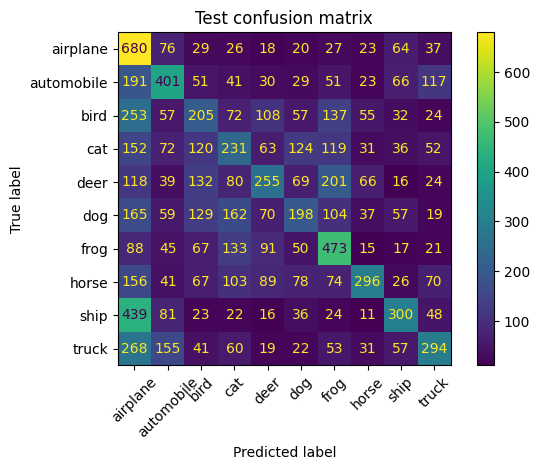

Macro precision: 0.3515
Macro recall: 0.3333
Macro F1: 0.3262


In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(np.asarray(metrics['confusion_matrix']), display_labels=CIFAR10_LABELS).plot(xticks_rotation=45)
plt.title('Test confusion matrix')
plt.tight_layout()
plt.show()
print('Macro precision:', round(metrics['precision_macro'], 4))
print('Macro recall:', round(metrics['recall_macro'], 4))
print('Macro F1:', round(metrics['f1_macro'], 4))

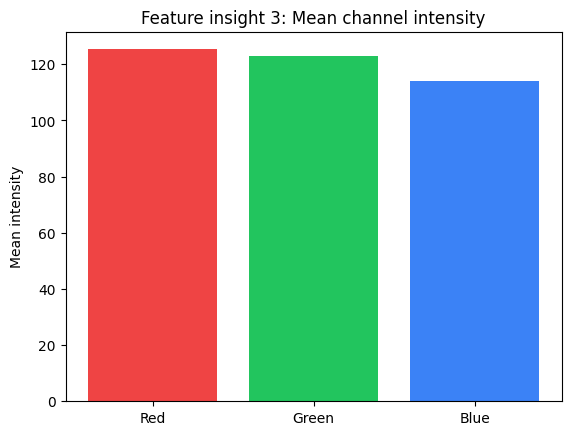

Interpretation: RGB channel balance explains how color contributes to scene identity, especially sky, vegetation, and road classes.


In [6]:
# Feature insight 3: channel differences
channel_means = X_train.mean(axis=(0,1,2))
plt.bar(['Red', 'Green', 'Blue'], channel_means, color=['#ef4444', '#22c55e', '#3b82f6'])
plt.title('Feature insight 3: Mean channel intensity')
plt.ylabel('Mean intensity')
plt.show()
print('Interpretation: RGB channel balance explains how color contributes to scene identity, especially sky, vegetation, and road classes.')

## 5. Prediction function
This helper demonstrates a single datapoint prediction using the saved model.

In [7]:
from PIL import Image
from src.model import load_model
from src.preprocessing import image_to_features

test_image = Image.fromarray(X_test[0])
features = image_to_features(test_image).reshape(1, -1)
prediction_id = int(load_model().predict(features)[0])
print('Predicted:', CIFAR10_LABELS[prediction_id])
print('Actual:', CIFAR10_LABELS[y_test[0]])

Predicted: cat
Actual: cat


## 6. Retraining
Run `python scripts/retrain.py --folder data/uploads` after uploading image folders named `0` through `9`. The existing fitted pipeline is updated incrementally with `partial_fit`, preserving the custom trained model.